# Tarea 7 · XGBoost para regresión

**Python · Concrete_Data.csv · Basada en `XGBoost.ipynb`**

Se entrena un XGBoost base, se ajustan seis hiperparámetros con `GridSearchCV` y se elige el número de árboles mediante parada temprana. Se comparan los modelos en prueba y se estiman resistencias para mezclas nuevas.

## 1. Carga y descripción de la base

La respuesta es **resistencia a compresión (MPa)**. Los predictores son cemento, escoria de alto horno, ceniza volante, agua, superplastificante, agregado grueso y agregado fino (todos en **kg/m³**), y edad de curado (**días**). Se conservan los ocho predictores. Las columnas de Boston y sus unidades no corresponden a esta base.

Se retiran únicamente duplicados exactos. Los ensayos distintos de la misma receta se conservan y se asignan juntos en cada partición. Las proporciones solicitadas se aplican a recetas, por lo que el porcentaje de filas puede variar.

In [1]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight"})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
import xgboost as xgb
from xgboost import XGBRegressor
from joblib import parallel_backend
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score

SEED = 42
print(f"XGBoost {xgb.__version__}")

Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1


XGBoost 3.4.1


In [2]:
ruta = next(
    (carpeta / "Concrete_Data.csv" for carpeta in (Path.cwd(), *Path.cwd().parents)
     if (carpeta / "Concrete_Data.csv").is_file()),
    None,
)
if ruta is None:
    raise FileNotFoundError("Abre el cuaderno dentro del proyecto que contiene Concrete_Data.csv.")

original = pd.read_csv(ruta)
columnas = [
    "cemento", "escoria", "ceniza_volante", "agua", "superplastificante",
    "agregado_grueso", "agregado_fino", "edad_dias", "resistencia_mpa",
]
if original.shape[1] != len(columnas):
    raise ValueError(f"Se esperaban 9 columnas, se encontraron {original.shape[1]}.")

df = original.set_axis(columnas, axis=1).apply(pd.to_numeric)
if not np.isfinite(df.to_numpy()).all():
    raise ValueError("Se encontraron valores faltantes o no finitos.")

print(f"Archivo: {ruta.name} | Filas originales: {len(df)} | Columnas: {df.shape[1]}")
print(f"Valores faltantes: {df.isna().sum().sum()} | Duplicados exactos: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
TARGET = "resistencia_mpa"
X = df.drop(columns=TARGET)
y = df[TARGET]
# Identificador de receta basado únicamente en las siete cantidades de mezcla.
grupos = df.groupby(columnas[:7], sort=False).ngroup()
print(f"Filas analizadas: {len(df)} | Recetas distintas: {grupos.nunique()}")
display(df.head(3))
display(df.describe().T.round(2))

Archivo: Concrete_Data.csv | Filas originales: 1030 | Columnas: 9
Valores faltantes: 0 | Duplicados exactos: 25
Filas analizadas: 1005 | Recetas distintas: 428


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535


,count,mean,std,min,25%,50%,75%,max
cemento,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
escoria,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
ceniza_volante,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
agua,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplastificante,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
agregado_grueso,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
agregado_fino,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
edad_dias,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
resistencia_mpa,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


## 2. Distribución de la resistencia y correlaciones

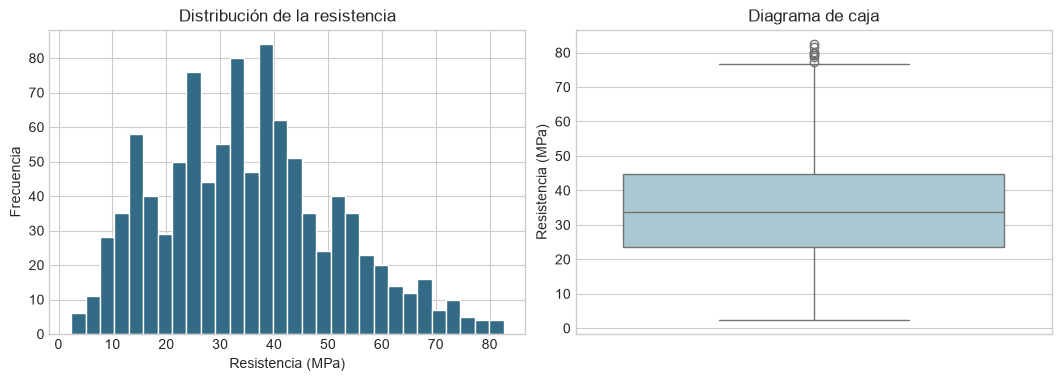

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), layout="constrained")
axes[0].hist(y, bins=30, color="#336b87", edgecolor="white")
axes[0].set(title="Distribución de la resistencia", xlabel="Resistencia (MPa)", ylabel="Frecuencia")
sns.boxplot(y=y, ax=axes[1], color="#a3cbd9")
axes[1].set(title="Diagrama de caja", ylabel="Resistencia (MPa)")
plt.show()

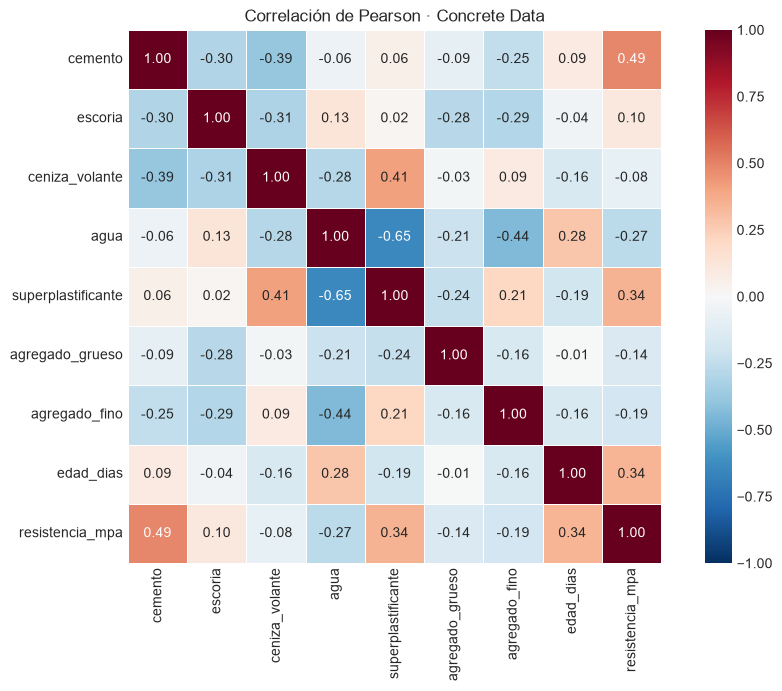

In [4]:
fig, ax = plt.subplots(figsize=(10, 6.8), layout="constrained")
corr = df.corr()
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="RdBu_r", square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlación de Pearson · Concrete Data")
plt.show()

## 3. Partición y modelo base

Se reserva el 20% de las recetas para prueba. El escalado era opcional en el ejemplo y sus modelos se entrenaban con las variables originales. Aquí se usan directamente las cantidades y la edad porque los árboles dividen por umbrales.

In [5]:
def dividir(indices, proporcion, semilla):
    divisor = GroupShuffleSplit(n_splits=1, test_size=proporcion, random_state=semilla)
    parte_a, parte_b = next(divisor.split(X.iloc[indices], groups=grupos.iloc[indices]))
    a, b = indices[parte_a], indices[parte_b]
    assert set(grupos.iloc[a]).isdisjoint(grupos.iloc[b])
    return a, b


def mostrar_particiones(**particiones):
    display(pd.DataFrame([
        {
            "Conjunto": nombre,
            "Filas": len(indices),
            "% de filas": 100 * len(indices) / len(df),
            "Recetas": grupos.iloc[indices].nunique(),
        }
        for nombre, indices in particiones.items()
    ]).round(2))

entrenamiento, prueba = dividir(np.arange(len(df)), 0.20, SEED)
X_train, X_test = X.iloc[entrenamiento], X.iloc[prueba]
y_train, y_test = y.iloc[entrenamiento], y.iloc[prueba]
grupos_train = grupos.iloc[entrenamiento]
mostrar_particiones(Entrenamiento=entrenamiento, Prueba=prueba)

def medir(observado, predicho):
    mse = mean_squared_error(observado, predicho)
    return {
        "MSE (MPa²)": mse,
        "RMSE (MPa)": np.sqrt(mse),
        "MAE (MPa)": mean_absolute_error(observado, predicho),
        "R²": r2_score(observado, predicho),
    }

def evaluar(observado, predicho):
    metricas = medir(observado, predicho)
    if (observado != 0).all():
        metricas["MAPE (%)"] = 100 * np.mean(np.abs((observado - predicho) / observado))
    return metricas


config = dict(objective="reg:squarederror", random_state=SEED, n_jobs=1, verbosity=0)
xgb_base = XGBRegressor(**config)
xgb_base.fit(X_train, y_train)
pred_base = xgb_base.predict(X_test)
metricas_base = evaluar(y_test, pred_base)
display(pd.Series(metricas_base, name="XGBoost base").round(4).to_frame())

,Conjunto,Filas,% de filas,Recetas
0,Entrenamiento,799,79.5,342
1,Prueba,206,20.5,86


,XGBoost base
MSE (MPa²),44.0899
RMSE (MPa),6.6400
MAE (MPa),4.6236
R²,0.8634
MAPE (%),13.4710


## 4. Búsqueda de hiperparámetros

Se conserva la rejilla de seis parámetros y cinco pliegues. El criterio es el menor RMSE medio de validación cruzada agrupada dentro de entrenamiento.

In [6]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3],
}
busqueda = GridSearchCV(
    XGBRegressor(**config), param_grid, cv=GroupKFold(n_splits=5),
    scoring="neg_root_mean_squared_error", n_jobs=4, error_score="raise",
)
with parallel_backend("threading"):
    busqueda.fit(X_train, y_train, groups=grupos_train)

cv_tabla = pd.DataFrame(busqueda.cv_results_["params"])
cv_tabla["RMSE CV (MPa)"] = -busqueda.cv_results_["mean_test_score"]
print(f"Combinaciones: {len(cv_tabla)} | Ajustes CV: {len(cv_tabla) * busqueda.n_splits_}")
print(f"Mejor RMSE medio de validación: {-busqueda.best_score_:.4f} MPa")
display(cv_tabla.nsmallest(8, "RMSE CV (MPa)").round(4).reset_index(drop=True))

Combinaciones: 216 | Ajustes CV: 1080
Mejor RMSE medio de validación: 5.4030 MPa


,colsample_bytree,learning_rate,max_depth,min_child_weight,n_estimators,subsample,RMSE CV (MPa)
0,0.8,0.05,5,1,300,0.8,5.4030
1,1.0,0.10,5,1,200,0.8,5.4415
2,1.0,0.05,5,3,300,0.8,5.4550
3,1.0,0.10,5,3,200,0.8,5.4553
4,1.0,0.05,5,1,300,0.8,5.4587
5,1.0,0.10,5,1,300,0.8,5.4640
6,0.8,0.10,3,1,300,0.8,5.4877
7,0.8,0.05,5,1,200,0.8,5.4892


## 5. Modelo optimizado y parada temprana

Se separa una validación interna del conjunto de entrenamiento. Se usa su RMSE para seleccionar la mejor iteración, con una paciencia de 20 rondas. Luego se reentrena con todo el conjunto de entrenamiento y el número de árboles elegido. La curva se obtiene del ajuste de parada temprana. Prueba queda reservada para medir el resultado.

In [7]:
ajuste, validacion = dividir(entrenamiento, 0.20, SEED + 1)
mostrar_particiones(Ajuste=ajuste, Validación=validacion, Prueba=prueba)
seleccion = XGBRegressor(
    **busqueda.best_params_, **config, eval_metric="rmse", early_stopping_rounds=20,
)
seleccion.fit(
    X.iloc[ajuste], y.iloc[ajuste],
    eval_set=[(X.iloc[ajuste], y.iloc[ajuste]), (X.iloc[validacion], y.iloc[validacion])],
    verbose=False,
)
arboles = seleccion.best_iteration + 1
historial = seleccion.evals_result()
print(f"Mejor iteración: {arboles} | Rondas ejecutadas: {len(historial['validation_1']['rmse'])}")
print(f"RMSE de validación en la mejor iteración: {seleccion.best_score:.4f} MPa")

params_finales = {**busqueda.best_params_, "n_estimators": arboles}
xgb_opt = XGBRegressor(**params_finales, **config)
xgb_opt.fit(X_train, y_train)
pred_opt = xgb_opt.predict(X_test)
metricas_opt = evaluar(y_test, pred_opt)
display(pd.Series(metricas_opt, name="XGBoost optimizado").round(4).to_frame())

,Conjunto,Filas,% de filas,Recetas
0,Ajuste,627,62.39,273
1,Validación,172,17.11,69
2,Prueba,206,20.50,86


Mejor iteración: 277 | Rondas ejecutadas: 297
RMSE de validación en la mejor iteración: 4.9295 MPa


,XGBoost optimizado
MSE (MPa²),36.3598
RMSE (MPa),6.0299
MAE (MPa),4.2388
R²,0.8873
MAPE (%),13.3727


## 6. Diagnóstico, importancia y curva de aprendizaje

La importancia corresponde a la ganancia normalizada (`gain`) del modelo ajustado. Describe cómo se emplean los predictores en los árboles.

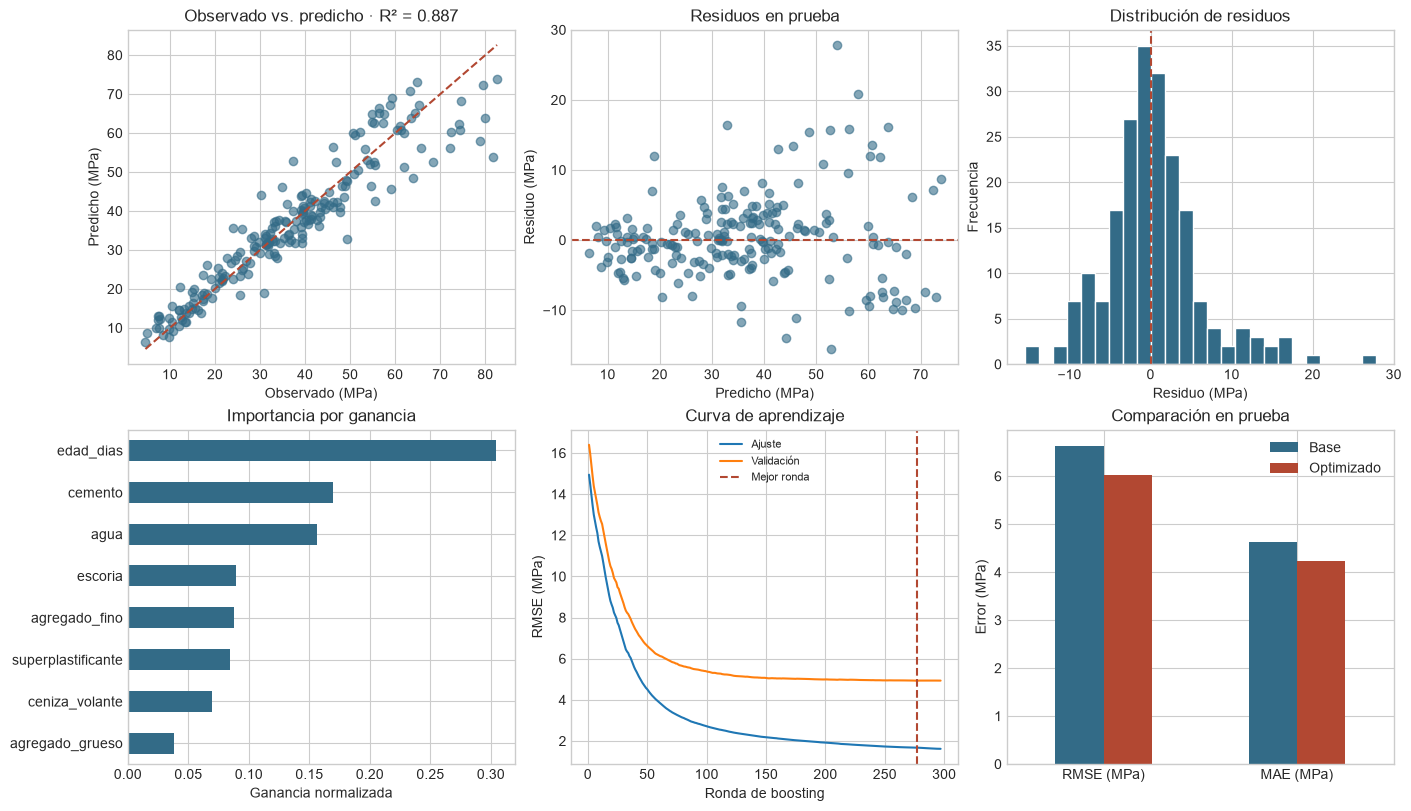

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
residuos = y_test.to_numpy() - pred_opt
lo, hi = min(y_test.min(), pred_opt.min()), max(y_test.max(), pred_opt.max())

ax = axes[0, 0]
ax.scatter(y_test, pred_opt, alpha=0.60, color="#336b87")
ax.plot([lo, hi], [lo, hi], "--", color="#b24832")
ax.set(title=f"Observado vs. predicho · R² = {metricas_opt['R²']:.3f}",
       xlabel="Observado (MPa)", ylabel="Predicho (MPa)")

ax = axes[0, 1]
ax.scatter(pred_opt, residuos, alpha=0.60, color="#336b87")
ax.axhline(0, color="#b24832", linestyle="--")
ax.set(title="Residuos en prueba", xlabel="Predicho (MPa)", ylabel="Residuo (MPa)")

ax = axes[0, 2]
ax.hist(residuos, bins=25, color="#336b87", edgecolor="white")
ax.axvline(0, color="#b24832", linestyle="--")
ax.set(title="Distribución de residuos", xlabel="Residuo (MPa)", ylabel="Frecuencia")

ganancia = pd.Series(xgb_opt.feature_importances_, index=X.columns).sort_values()
ganancia.plot.barh(ax=axes[1, 0], color="#336b87")
axes[1, 0].set(title="Importancia por ganancia", xlabel="Ganancia normalizada")

ax = axes[1, 1]
for clave, etiqueta in (("validation_0", "Ajuste"), ("validation_1", "Validación")):
    rmse = historial[clave]["rmse"]
    ax.plot(np.arange(1, len(rmse) + 1), rmse, label=etiqueta)
ax.axvline(arboles, color="#b24832", linestyle="--", label="Mejor ronda")
ax.set(title="Curva de aprendizaje", xlabel="Ronda de boosting", ylabel="RMSE (MPa)")
ax.legend(fontsize=8)

comparacion = pd.DataFrame({"Base": metricas_base, "Optimizado": metricas_opt})
comparacion.loc[["RMSE (MPa)", "MAE (MPa)"]].plot.bar(ax=axes[1, 2], rot=0,
                                                     color=["#336b87", "#b24832"])
axes[1, 2].set(title="Comparación en prueba", ylabel="Error (MPa)")
plt.show()

## 7. Validación cruzada final y resumen

Se conservan diez pliegues para describir la variación del modelo optimizado dentro de entrenamiento. Se usan parámetros ya seleccionados sobre ese conjunto. La evaluación externa a la búsqueda es la tabla de prueba. La desviación estándar resume la dispersión entre pliegues.

In [9]:
with parallel_backend("threading"):
    rmse_cv = -cross_val_score(
        XGBRegressor(**params_finales, **config),
        X_train, y_train, groups=grupos_train, cv=GroupKFold(n_splits=10),
        scoring="neg_root_mean_squared_error", n_jobs=4, error_score="raise",
    )
display(pd.Series(rmse_cv, index=np.arange(1, 11), name="RMSE (MPa)")
        .rename_axis("Pliegue").round(4).to_frame())
print(f"RMSE CV medio: {rmse_cv.mean():.4f} MPa | Desviación estándar: {rmse_cv.std(ddof=1):.4f} MPa")
display(comparacion.round(4))

diferencia = metricas_base["RMSE (MPa)"] - metricas_opt["RMSE (MPa)"]
mejor = "el optimizado" if diferencia > 0 else "el base" if diferencia < 0 else "ambos"
print(f"Conclusión · Menor RMSE en prueba: {mejor}. "
      f"Base: {metricas_base['RMSE (MPa)']:.2f} MPa. Optimizado: {metricas_opt['RMSE (MPa)']:.2f} MPa "
      f"(MAE {metricas_opt['MAE (MPa)']:.2f} MPa, R² {metricas_opt['R²']:.4f}).")
print(f"Mayor ganancia normalizada en el ajuste optimizado: {ganancia.idxmax()}.")

,RMSE (MPa)
Pliegue,
1,4.6628
2,5.7368
3,7.3753
4,4.3761
5,4.7118
6,5.8251
7,5.0915
8,5.1790
9,4.5681


RMSE CV medio: 5.3500 MPa | Desviación estándar: 0.9069 MPa


,Base,Optimizado
MSE (MPa²),44.0899,36.3598
RMSE (MPa),6.6400,6.0299
MAE (MPa),4.6236,4.2388
R²,0.8634,0.8873
MAPE (%),13.4710,13.3727


Conclusión · Menor RMSE en prueba: el optimizado. Base: 6.64 MPa. Optimizado: 6.03 MPa (MAE 4.24 MPa, R² 0.8873).
Mayor ganancia normalizada en el ajuste optimizado: edad_dias.


## 8. Predicción individual, por lote y en contexto

Se usa una receta hipotética con tres edades. La posición de la predicción individual se calcula frente a la distribución observada de resistencias. Las cantidades se normalizan por sus rangos observados para compararlas en una sola gráfica.

Predicción individual a 28 días: 43.34 MPa


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,prediccion_mpa
7 días,300,90,75,175,7,1000,760,7,30.540001
28 días,300,90,75,175,7,1000,760,28,43.340000
90 días,300,90,75,175,7,1000,760,90,52.939999


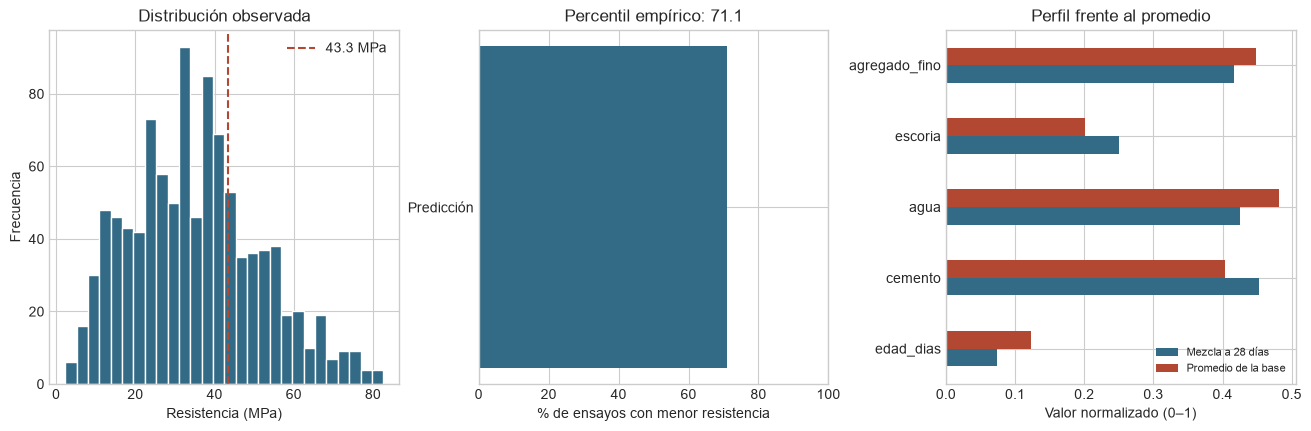

In [10]:
mezclas = pd.DataFrame([
    [300, 90, 75, 175, 7, 1000, 760, 7],
    [300, 90, 75, 175, 7, 1000, 760, 28],
    [300, 90, 75, 175, 7, 1000, 760, 90],
], columns=X.columns, index=["7 días", "28 días", "90 días"])

registro = mezclas.loc[["28 días"]]
prediccion = xgb_opt.predict(registro)[0]
print(f"Predicción individual a 28 días: {prediccion:.2f} MPa")
display(mezclas.assign(prediccion_mpa=xgb_opt.predict(mezclas)).round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
axes[0].hist(y, bins=28, color="#336b87", edgecolor="white")
axes[0].axvline(prediccion, color="#b24832", linestyle="--", label=f"{prediccion:.1f} MPa")
axes[0].set(title="Distribución observada", xlabel="Resistencia (MPa)", ylabel="Frecuencia")
axes[0].legend()

percentil = 100 * (y < prediccion).mean()
axes[1].barh(["Predicción"], [percentil], color="#336b87")
axes[1].set(xlim=(0, 100), xlabel="% de ensayos con menor resistencia", title=f"Percentil empírico: {percentil:.1f}")

claves = ganancia.nlargest(5).index
minimos, rangos = X[claves].min(), X[claves].max() - X[claves].min()
perfiles = pd.DataFrame({
    "Mezcla a 28 días": (registro.iloc[0][claves] - minimos) / rangos,
    "Promedio de la base": (X[claves].mean() - minimos) / rangos,
})
perfiles.plot.barh(ax=axes[2], color=["#336b87", "#b24832"])
axes[2].set(title="Perfil frente al promedio", xlabel="Valor normalizado (0–1)")
axes[2].legend(fontsize=8)
plt.show()